# 03 — Comparación de 8, 16 y 32 frames por clip

El plan fija **16 frames** por clip. Antes de darlo por bueno se compara contra
8 y 32 con lo que se puede **medir sin entrenar**:

| Medida | Qué responde |
|---|---|
| Separación temporal entre frames | ¿Cuánto movimiento queda "entre" dos frames que el modelo no ve? |
| Distancia al pico de movimiento | ¿Qué tan cerca cae un frame muestreado del momento de más acción? |
| Redundancia | ¿Los frames vecinos son casi iguales (se desperdicia cómputo)? |
| Costo | Tiempo de extracción, memoria del tensor y tiempo de MobileNetV2 por clip. |

**Límite importante:** nada de esto mide la *exactitud* del modelo. Saber si
8, 16 o 32 clasifica mejor requiere entrenar con cada valor (fase de
entrenamiento); aquí solo se reúne la evidencia de costo y cobertura.

Se usa `extract_frames` de `src/preprocessing/video_pipeline.py`, el mismo
código que usará el entrenamiento.

## 1. Imports y muestra de videos

In [1]:
import sys
import time
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torchvision.models import mobilenet_v2

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT))

from src.preprocessing.video_pipeline import extract_frames, resize_and_convert

COLORES = {"violencia": "#d1495b", "no_violencia": "#2e86ab"}
VALORES_T = (8, 16, 32)
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})

# Metadatos generados por 02_eda_datasets.ipynb (data/processed no se versiona).
meta = pd.read_csv(ROOT / "data" / "processed" / "metadata_real_life.csv", keep_default_na=False)

# Se usan clips de hasta 30 s: son el 99,8 % del dataset y el perfil de
# movimiento exige decodificar el video completo (los de varios minutos
# tardarian demasiado y igual se van a tratar aparte, ver notebook 02).
POR_CLASE = 40
muestra = (meta[meta["segundos"] <= 30]
           .groupby("clase", group_keys=False)
           .sample(POR_CLASE, random_state=42)
           .reset_index(drop=True))
print(muestra.groupby("clase").size().to_string())

clase
no_violencia    40
violencia       40


## 2. Perfil de movimiento de cada video

Para cada video se decodifican **todos** los frames (en gris y a 64×64, por
velocidad) y se calcula la diferencia media entre frames consecutivos. Esa
curva es la "cantidad de movimiento" en el tiempo; su máximo (suavizado ~0,5 s)
es el momento de mayor acción, que es el que un buen muestreo no debería perder.

In [2]:
def perfil_movimiento(ruta: str) -> tuple[np.ndarray, float]:
    """Devuelve (movimiento por frame, fps) leyendo el video completo.

    El movimiento del frame i es la diferencia absoluta media entre el
    frame i y el i-1 (el primero vale 0), en escala de grises 64x64.
    """
    cap = cv2.VideoCapture(ruta)
    fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
    previo, mov = None, []
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        g = cv2.resize(cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY), (64, 64),
                       interpolation=cv2.INTER_AREA).astype(np.float32)
        mov.append(0.0 if previo is None else float(np.abs(g - previo).mean()))
        previo = g
    cap.release()
    return np.array(mov), fps


def indices_muestreados(total: int, n: int) -> np.ndarray:
    """Mismos indices que usa extract_frames (np.linspace con enteros)."""
    return np.linspace(0, total - 1, n, dtype=int)


perfiles = {}
t0 = time.time()
for _, v in muestra.iterrows():
    perfiles[v["ruta"]] = perfil_movimiento(v["ruta"])
print(f"{len(perfiles)} perfiles en {time.time() - t0:.0f} s")

80 perfiles en 12 s


## 3. Medidas por video y por valor de T

- **Separación**: segundos entre dos frames muestreados consecutivos
  (duración real del clip dividida por T − 1).
- **Distancia al pico**: segundos entre el frame de mayor movimiento
  (suavizado) y el frame muestreado más cercano.
- **Redundancia**: diferencia media entre frames muestreados vecinos,
  en gris 64×64 (más baja = frames más parecidos entre sí).

In [3]:
def suavizar(x: np.ndarray, ventana: int) -> np.ndarray:
    """Media movil simple; evita que un solo frame ruidoso sea 'el pico'."""
    ventana = max(1, ventana)
    return np.convolve(x, np.ones(ventana) / ventana, mode="same")


filas = []
for _, v in muestra.iterrows():
    mov, fps = perfiles[v["ruta"]]
    total = len(mov)  # frames realmente decodificados (mas fiable que el header)
    pico = int(np.argmax(suavizar(mov, int(round(fps * 0.5)))))
    for n in VALORES_T:
        idx = indices_muestreados(total, n)
        # Redundancia: diferencia entre frames muestreados vecinos. Se
        # reutiliza el perfil solo para la distancia; para la redundancia
        # hay que releer esos frames, por eso se usa extract_frames abajo.
        filas.append({
            "clase": v["clase"], "ruta": v["ruta"], "T": n,
            "separacion_s": (total / fps) / (n - 1),
            "dist_pico_s": float(np.abs(idx - pico).min() / fps),
        })
res = pd.DataFrame(filas)

# Redundancia y tiempo de extraccion usando el extractor real del proyecto.
red, tiempos = [], []
for _, v in muestra.iterrows():
    for n in VALORES_T:
        t0 = time.perf_counter()
        frames = extract_frames(v["ruta"], n)
        tiempos.append(time.perf_counter() - t0)
        g = np.array([cv2.resize(cv2.cvtColor(f, cv2.COLOR_BGR2GRAY), (64, 64),
                                 interpolation=cv2.INTER_AREA) for f in frames],
                     dtype=np.float32)
        red.append(float(np.abs(np.diff(g, axis=0)).mean()))
res["redundancia"] = red
res["extraccion_ms"] = np.array(tiempos) * 1000

tabla = res.groupby("T")[["separacion_s", "dist_pico_s", "redundancia", "extraccion_ms"]].agg(
    ["mean", "median"]).round(3)
print(tabla.to_string())

   separacion_s        dist_pico_s        redundancia         extraccion_ms         
           mean median        mean median        mean  median          mean   median
T                                                                                   
8         0.702  0.714       0.195  0.204      27.101  24.580       109.868   57.863
16        0.328  0.333       0.079  0.080      20.481  18.043       210.416  106.372
32        0.159  0.161       0.039  0.037      14.834  12.419       404.388  206.628


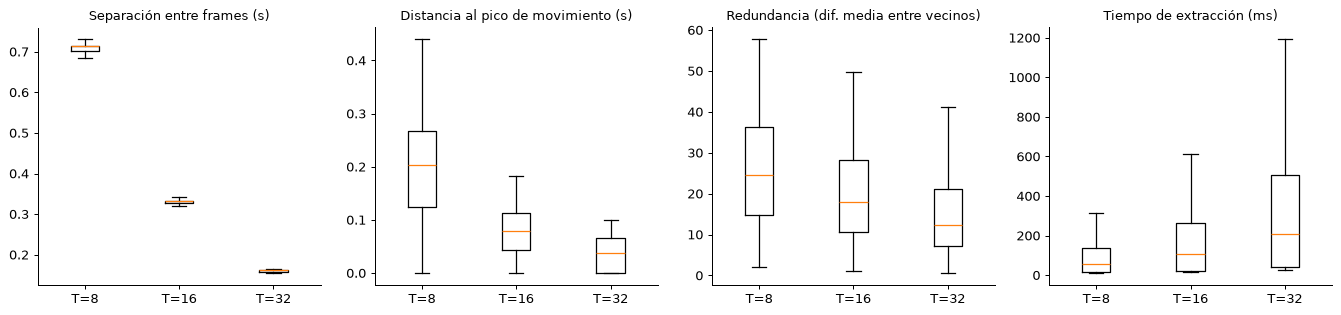

In [4]:
fig, ejes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, col, titulo in zip(
        ejes,
        ["separacion_s", "dist_pico_s", "redundancia", "extraccion_ms"],
        ["Separación entre frames (s)", "Distancia al pico de movimiento (s)",
         "Redundancia (dif. media entre vecinos)", "Tiempo de extracción (ms)"]):
    datos = [res.loc[res["T"] == n, col] for n in VALORES_T]
    ax.boxplot(datos, tick_labels=[f"T={n}" for n in VALORES_T], showfliers=False)
    ax.set_title(titulo, fontsize=10)
plt.tight_layout()
plt.show()

## 4. Costo de cómputo: MobileNetV2 con T frames

El extractor por frame de la arquitectura candidata es MobileNetV2; su costo
crece linealmente con T. Se mide el tiempo real del *forward* de un clip en
CPU. Los pesos no afectan la latencia, así que se usa `weights=None` (sin
descargar nada). Es CPU de esta máquina, no la de la demo final.

In [5]:
torch.set_num_threads(max(1, torch.get_num_threads()))
backbone = mobilenet_v2(weights=None).features.eval()

costo = []
with torch.no_grad():
    for n in VALORES_T:
        clip = torch.randn(n, 3, 224, 224)  # un clip: T frames como batch
        backbone(clip)  # calentamiento
        tiempos_fw = []
        for _ in range(5):
            t0 = time.perf_counter()
            backbone(clip)
            tiempos_fw.append(time.perf_counter() - t0)
        costo.append({
            "T": n,
            "forward_ms_por_clip": round(float(np.median(tiempos_fw)) * 1000, 1),
            "tensor_MB_por_clip": round(n * 3 * 224 * 224 * 4 / 1e6, 1),
            "tensor_MB_batch8": round(8 * n * 3 * 224 * 224 * 4 / 1e6, 1),
        })
costo = pd.DataFrame(costo)
print(costo.to_string(index=False))

 T  forward_ms_por_clip  tensor_MB_por_clip  tensor_MB_batch8
 8                 70.6                 4.8              38.5
16                185.9                 9.6              77.1
32                425.0                19.3             154.1


## 5. Comparación visual

Un clip de `Violence` representado con 8, 16 y 32 frames (columna = frame
muestreado, ya a 224×224 como los vería el modelo). Debajo de cada tira se
dibuja el perfil de movimiento y los instantes muestreados.

Clip: V_827.mp4 (4.8 s, 30 fps)


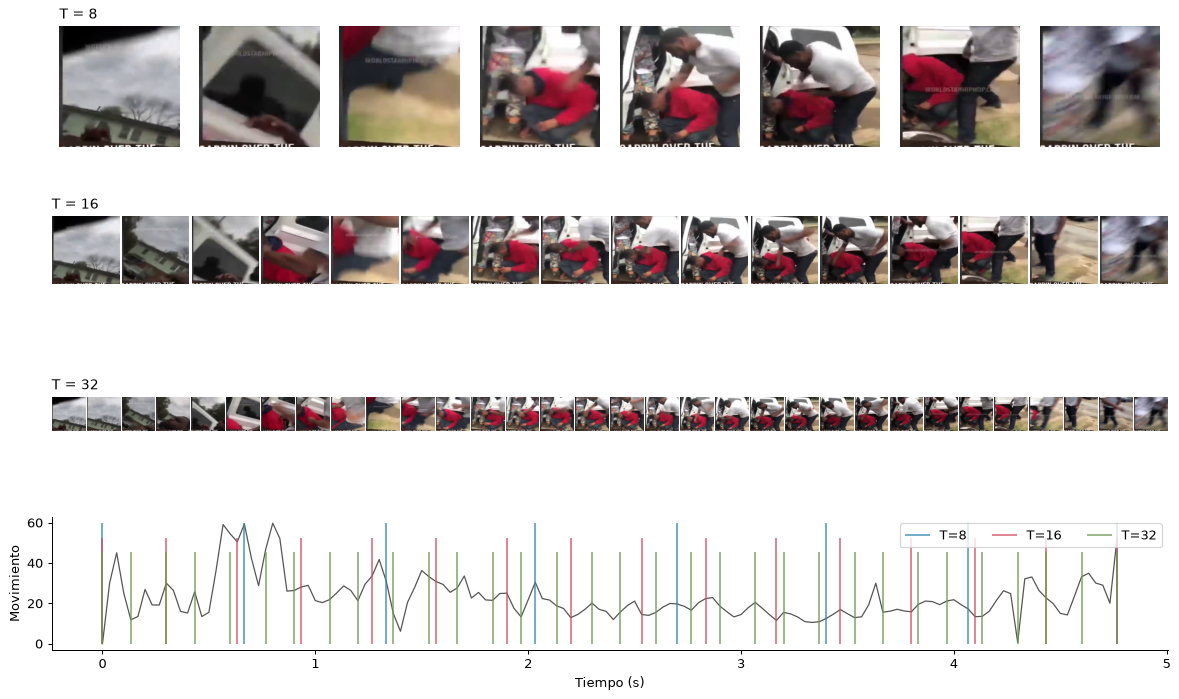

In [6]:
# Se elige el clip de Violence con mas movimiento sostenido (percentil 90).
# Con el maximo se elegian clips con cortes de escena, cuyo salto brusco de
# un frame a otro parece "movimiento" sin serlo.
cand = muestra[muestra["clase"] == "violencia"]
elegido = max(cand["ruta"], key=lambda r: np.percentile(perfiles[r][0], 90))
mov, fps = perfiles[elegido]
print("Clip:", Path(elegido).name, f"({len(mov) / fps:.1f} s, {fps:.0f} fps)")

fig = plt.figure(figsize=(16, 9))
gs = fig.add_gridspec(4, 1, height_ratios=[1, 1, 1, 1.1], hspace=0.35)
for fila, n in enumerate(VALORES_T):
    sub = gs[fila].subgridspec(1, n, wspace=0.03)
    frames = resize_and_convert(extract_frames(elegido, n), 224)  # RGB 224x224
    for j in range(n):
        ax = fig.add_subplot(sub[0, j])
        ax.imshow(frames[j])
        ax.axis("off")
        if j == 0:
            ax.set_title(f"T = {n}", loc="left", fontsize=11)

ax = fig.add_subplot(gs[3])
t = np.arange(len(mov)) / fps
ax.plot(t, mov, color="#555", lw=1)
marcas = ["#2e86ab", "#d1495b", "#6a994e"]
for n, c, dy in zip(VALORES_T, marcas, (0, 1, 2)):
    idx = indices_muestreados(len(mov), n)
    ax.vlines(idx / fps, 0, mov.max() * (1 - 0.12 * dy), color=c, alpha=0.7,
              label=f"T={n}")
ax.set_xlabel("Tiempo (s)")
ax.set_ylabel("Movimiento")
ax.legend(ncol=3, loc="upper right")
plt.show()

## 6. Conclusiones

Medido sobre 80 clips de Real Life (40 por clase, ≤ 30 s), en la CPU de esta
máquina (los tiempos varían ±10 % entre ejecuciones):

| T | Separación media | Forward MobileNetV2 por clip | Tensor de entrada, batch de 8 | Extracción (mediana) |
|---|---|---|---|---|
| 8 | 0,70 s | ≈ 70–85 ms | 38,5 MB | ≈ 55 ms |
| 16 | 0,33 s | ≈ 195–200 ms | 77,1 MB | ≈ 100 ms |
| 32 | 0,16 s | ≈ 430 ms | 154,1 MB | ≈ 192 ms |

- **Costo:** pasar de 16 a 32 frames multiplica por ~2 el tiempo del extractor de
  MobileNetV2 y duplica la memoria del batch. Pasar de 16 a 8 lo reduce a ~35–45 %.
- **Cobertura:** con 8 frames queda ~0,7 s entre muestras. Un empujón o un
  arrebato de menos de un segundo podría caer entre dos frames y no verse (esto es
  una inferencia a partir de la separación, **no** algo medido con el modelo). Con
  16 la separación baja a ~0,33 s y con 32 a ~0,16 s.
- **Redundancia:** la diferencia media entre frames vecinos baja de 27 (T=8) a 20
  (T=16) y 15 (T=32): al duplicar T, los frames se parecen más entre sí, o sea,
  cada frame extra aporta menos información nueva.
- **Extracción vs. modelo:** extraer 16 frames con `cv2.set(POS_FRAMES)` tarda
  ~100 ms (mediana), del mismo orden que el forward (~200 ms). Para entrenar
  conviene **precalcular y guardar los tensores** en `data/processed/` en lugar de
  releer el video en cada epoch.

**Recomendación (a confirmar con el equipo):** mantener **16** como valor
por defecto, como pide el plan: es el punto intermedio entre cobertura y costo.
Pasar a 32 duplica el costo sin una ganancia que podamos justificar todavía, y 8
arriesga perder eventos cortos.

**Lo que este notebook NO demuestra:**

- No dice qué valor clasifica mejor. Eso exige entrenar con cada T; se propone
  hacerlo en la fase de entrenamiento sobre un subconjunto pequeño (p. ej.
  8 vs 16) y reportar la métrica medida.
- "Distancia al pico" depende casi por completo de la separación (≈ ¼ de ella), así
  que es poco informativa por sí sola. Además, en clips con cortes de escena el
  "pico" puede ser un corte y no una pelea.
- Los tiempos son de una CPU concreta, y solo se usó Real Life; falta repetir con
  RWF-2000 (cámaras de vigilancia, 5 s a 30 fps) cuando esté disponible localmente.
